# Import Libraries

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import os
import matplotlib.pyplot as plt
from keras.models import Model, Sequential
from keras.layers import Dense, Input, Dropout, GlobalAveragePooling2D, Flatten, Conv2D, BatchNormalization, Activation, MaxPooling2D
from keras.optimizers import Adam, SGD, RMSprop
from tqdm import tqdm
from sklearn.metrics import confusion_matrix
from sklearn.utils import shuffle                      
import cv2                                 
import tensorflow as tf  
import warnings
warnings.filterwarnings('ignore', category=DeprecationWarning)

# Load and Preprocess the Dataset

In [2]:
class_names = ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
class_names_label = {class_name:i for i, class_name in enumerate(class_names)}

nb_classes = len(class_names)

IMAGE_SIZE = (50, 50)

def load_data():
    datasets = [r"C:\Users\HP\Desktop\train"]

    output = []
    
    # Iterate through training and test sets
    for dataset in datasets:
        
        images = []
        labels = []
        
        print("Loading {}".format(dataset))
        
        # Iterate through each folder corresponding to a category
        for folder in os.listdir(dataset):
            label = class_names_label[folder]
            
            count = 0
            # Iterate through each image in our folder
            for file in tqdm(os.listdir(os.path.join(dataset, folder))):
                
                # Get the path name of the image
                img_path = os.path.join(os.path.join(dataset, folder), file)
                
                # Open and resize the img
#                 image = cv2.imread(img_path)
                image = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
#                 image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
                image = cv2.resize(image, IMAGE_SIZE) 
                
                # Append the image and its corresponding label to the output
                images.append(image)
                labels.append(label)
                
                # Taking 2k images from of each type because of MemoryError
                count = count + 1
                if count == 5000:
                    break
                
        images = np.array(images, dtype = 'float32')
        labels = np.array(labels, dtype = 'int32')   
        
        output.append((images, labels))

    return output

In [3]:
(images, labels) = load_data()[0]

Loading C:\Users\HP\Desktop\train


100%|██████████████████████████████████████████████████████████████████████████████| 3205/3205 [00:36<00:00, 88.43it/s]


In [4]:
permutation  = np.random.permutation(len(images))

shuffled_images = images[permutation]
shuffled_labels = labels[permutation]

In [5]:
# Import the train_test_split function from scikit-learn
from sklearn.model_selection import train_test_split

# Split the shuffled images and labels into training and testing sets
# with 10% of the data reserved for testing, and shuffle the data
train_images, test_images, train_labels, test_labels = train_test_split(shuffled_images, shuffled_labels, test_size=0.1, shuffle=True)

# Check the shapes of the resulting datasets
train_images.shape, train_labels.shape, test_images.shape, test_labels.shape


((23991, 50, 50), (23991,), (2666, 50, 50), (2666,))

In [6]:
# Normalize the images to a range of 0 to 1
train_images = train_images / 255.0 
test_images = test_images / 255.0

# Visualize Some Images

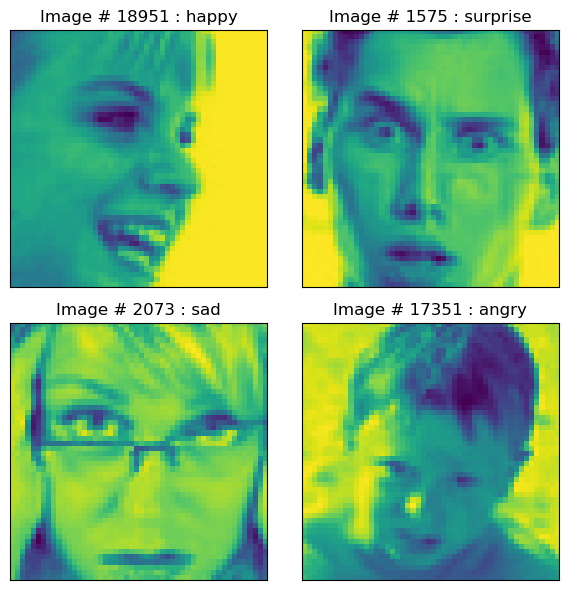

In [7]:

# Function to display a specified number of random images from the dataset
def display_random_images(class_names, images, labels, num_images=4):   
    plt.figure(figsize=(6, 6))
    
    # Loop to display the specified number of random images
    for i in range(num_images):
        index = np.random.randint(images.shape[0])  # Randomly select an image index
        plt.subplot(2, 2, i + 1)  # Create a subplot for each image
        plt.imshow(images[index])  # Display the image
        plt.xticks([])  # Remove x-axis ticks
        plt.yticks([])  # Remove y-axis ticks
        plt.grid(False)  # Disable the grid
        plt.title('Image # {} : '.format(index) + class_names[labels[index]])  # Add a title with the image index and class name
    
    plt.tight_layout()  # Adjust the subplots to fit in the figure area
    plt.show()  # Display the figure
    
# Call the function to display random images from the training dataset
display_random_images(class_names, train_images, train_labels)


# Build the Model

In [8]:
# Define a sequential model using Keras
model2 = tf.keras.Sequential([
    # First convolutional layer with 16 filters, 3x3 kernel size, ReLU activation, and input shape (50, 50, 1)
    tf.keras.layers.Conv2D(16, (3, 3), activation='relu', input_shape=(50, 50, 1)),
    tf.keras.layers.BatchNormalization(),  # Batch normalization layer
    tf.keras.layers.MaxPooling2D(2, 2),  # Max pooling layer with 2x2 pool size
    tf.keras.layers.Dropout(0.2),  # Dropout layer with 20% dropout rate
    
    # Second convolutional layer with 32 filters and 3x3 kernel size
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.BatchNormalization(),  # Batch normalization layer
    tf.keras.layers.MaxPooling2D(2, 2),  # Max pooling layer with 2x2 pool size
    tf.keras.layers.Dropout(0.2),  # Dropout layer with 20% dropout rate
    
    # Third convolutional layer with 64 filters and 3x3 kernel size
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.BatchNormalization(),  # Batch normalization layer
    tf.keras.layers.MaxPooling2D(2, 2),  # Max pooling layer with 2x2 pool size
    tf.keras.layers.Dropout(0.2),  # Dropout layer with 20% dropout rate
    
    # Fourth convolutional layer with 128 filters and 3x3 kernel size
    tf.keras.layers.Conv2D(128, (3, 3), activation='relu'),
    tf.keras.layers.BatchNormalization(),  # Batch normalization layer
    tf.keras.layers.MaxPooling2D(2, 2),  # Max pooling layer with 2x2 pool size
    tf.keras.layers.Dropout(0.2),  # Dropout layer with 20% dropout rate
    
    tf.keras.layers.Flatten(),  # Flatten layer to reshape input for the dense layer
    tf.keras.layers.Dense(128, activation='relu'),  # Fully connected layer with 128 units and ReLU activation
    tf.keras.layers.Dropout(0.2),  # Dropout layer with 20% dropout rate
    
    tf.keras.layers.Dense(7, activation='softmax')  # Output layer with 7 units and softmax activation for classification
])

# Compile the model with Adam optimizer, sparse categorical crossentropy loss, and accuracy metric
model2.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# model2.summary()


# Train the Model

In [9]:
history = model2.fit(train_images, train_labels, epochs=30, validation_split = 0.1)

Epoch 1/30


675/675 [==============================] - 37s 44ms/step - loss: 1.8390 - accuracy: 0.2514 - val_loss: 2.0889 - val_accuracy: 0.2425
Epoch 2/30
675/675 [==============================] - 32s 47ms/step - loss: 1.6295 - accuracy: 0.3517 - val_loss: 1.8825 - val_accuracy: 0.2575
Epoch 3/30
675/675 [==============================] - 32s 47ms/step - loss: 1.5372 - accuracy: 0.4010 - val_loss: 1.4199 - val_accuracy: 0.4433
Epoch 4/30
675/675 [==============================] - 29s 42ms/step - loss: 1.4666 - accuracy: 0.4281 - val_loss: 1.6668 - val_accuracy: 0.3371
Epoch 5/30
675/675 [==============================] - 29s 44ms/step - loss: 1.4214 - accuracy: 0.4522 - val_loss: 1.5570 - val_accuracy: 0.3913
Epoch 6/30
675/675 [==============================] - 29s 43ms/step - loss: 1.3811 - accuracy: 0.4624 - val_loss: 1.3410 - val_accuracy: 0.4783
Epoch 7/30
675/675 [==============================] - 28s 42ms/step - loss: 1.3480 - accuracy: 0.4787 - val_loss: 1.3085 - val_accurac

# Evaluate the Model

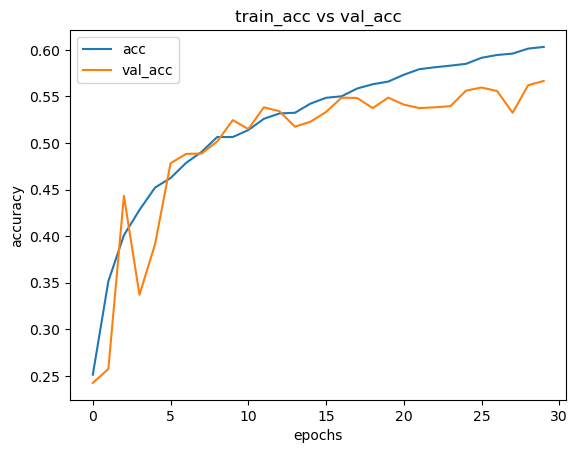

In [10]:
plt.plot(history.history['accuracy'], label = "acc")
plt.plot(history.history['val_accuracy'], label = "val_acc")
plt.title("train_acc vs val_acc")
plt.ylabel("accuracy")
plt.xlabel("epochs")
plt.legend()

# Make Predictions

84/84 [==============================] - 2s 14ms/step


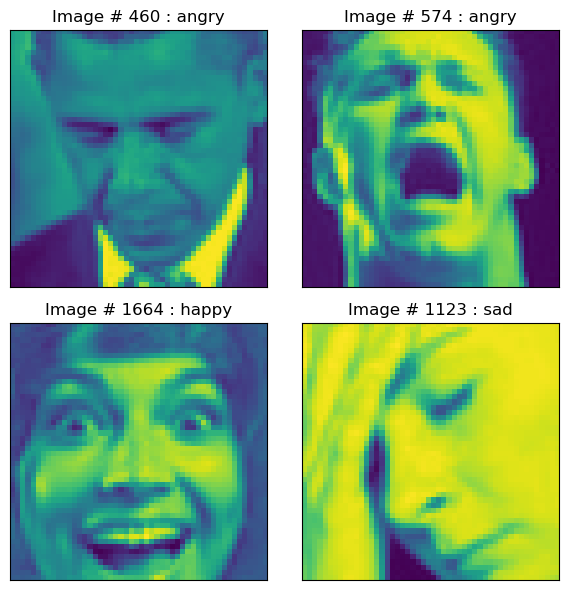

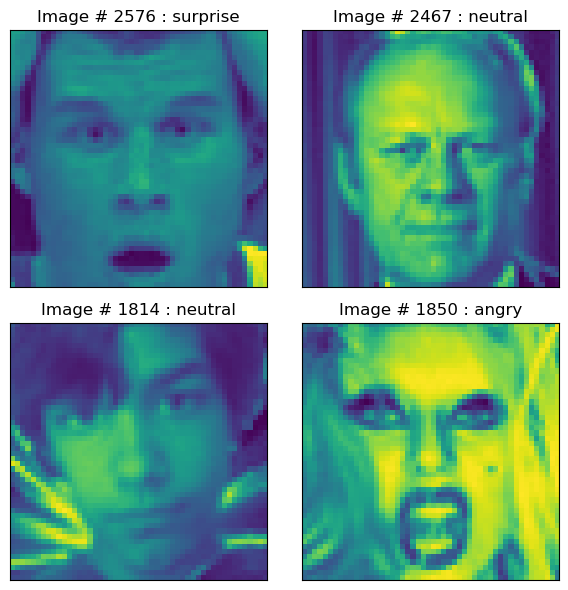

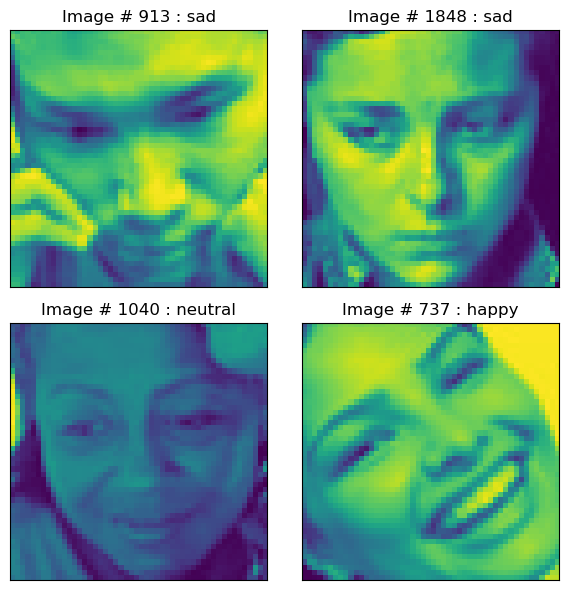

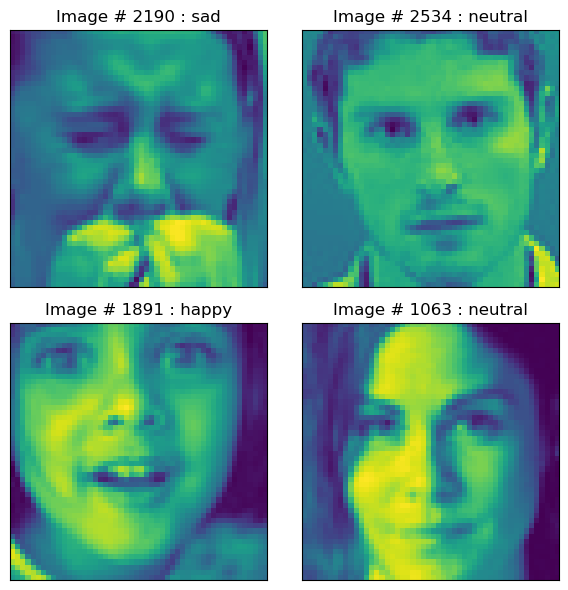

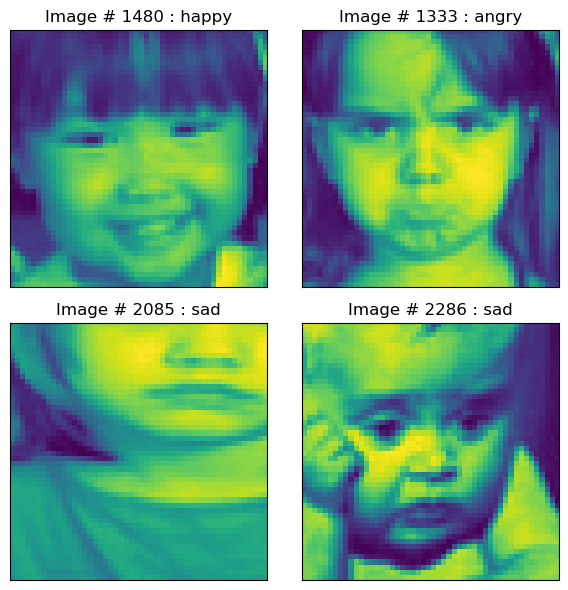

In [11]:
def display_random_image(class_names, test_images, pred_labels):
    index = random.randint(0, len(test_images) - 1)  # Randomly select an image index
    image = test_images[index]
    label = pred_labels[index]
    
    plt.imshow(image)
    plt.title(f"Predicted: {class_names[label]}")
    plt.axis('off')
    plt.show()

# Your existing code
predictions = model2.predict(test_images)     # Vector of probabilities
pred_labels = np.argmax(predictions, axis=1)  # We take the highest probability

# Display predicted labels
for i in range(5):
    display_random_images(class_names, test_images, pred_labels)


84/84 [==============================] - 2s 18ms/step


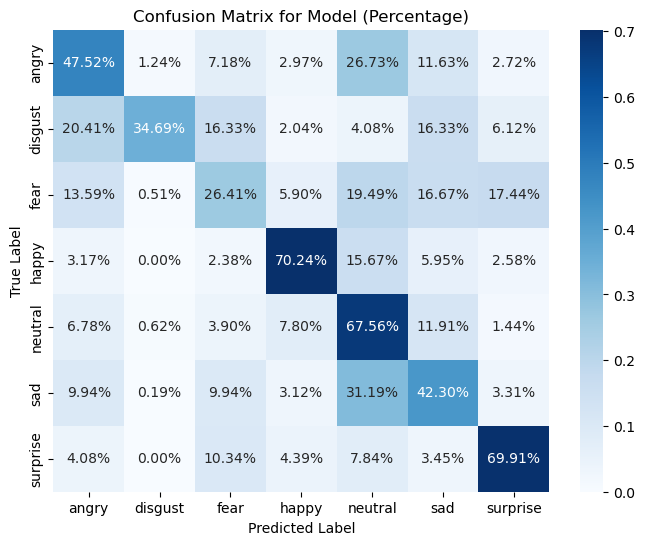

In [13]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# Generate predictions for the test set
predictions = model2.predict(test_images)  # Vector of probabilities
pred_labels = np.argmax(predictions, axis=1)  # Take the highest probability

# Compute the confusion matrix
conf_matrix = confusion_matrix(test_labels, pred_labels)

# Normalize the confusion matrix by dividing by the sum of each row
conf_matrix_normalized = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]

# Display the normalized confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_normalized, annot=True, fmt='.2%', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for Model (Percentage)')
plt.show()


In [14]:
# Generate the classification report
class_report = classification_report(test_labels, pred_labels, target_names=class_names)
print("Classification Report:\n")
print(class_report)

Classification Report:

              precision    recall  f1-score   support

       angry       0.52      0.48      0.50       404
     disgust       0.61      0.35      0.44        49
        fear       0.40      0.26      0.32       390
       happy       0.77      0.70      0.74       504
     neutral       0.42      0.68      0.52       487
         sad       0.50      0.42      0.46       513
    surprise       0.65      0.70      0.67       319

    accuracy                           0.54      2666
   macro avg       0.55      0.51      0.52      2666
weighted avg       0.55      0.54      0.53      2666

